# House Price Prediction in King County, USA

**Goal:** predict the sale price of residential houses in King County (Seattle area) using features such as living area, building grade, bathrooms, floors and waterfront view.

**Context:** final project of the *IBM Data Analysis with Python* certification. The scenario is a data analyst at a real estate investment trust that wants to start investing in residential properties and needs to estimate market prices.

**Dataset:** house sales between May 2014 and May 2015 (~21,600 records). Source: [Kaggle – House Sales Prediction](https://www.kaggle.com/harlfoxem/housesalesprediction), slightly modified by IBM for the course.

**Workflow:** data loading → cleaning → exploratory analysis → model development → model evaluation.

## 1. Data loading and first look

In [25]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler,PolynomialFeatures
from sklearn.linear_model import LinearRegression
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
url = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DA0101EN-SkillsNetwork/labs/FinalModule_Coursera/data/kc_house_data_NaN.csv"
df = pd.read_csv(url)

In [26]:
df.head()

,Unnamed: 0,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,0,7129300520,20141013T000000,221900.0,3.0,1.00,1180,5650,1.0,0,...,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,1,6414100192,20141209T000000,538000.0,3.0,2.25,2570,7242,2.0,0,...,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,2,5631500400,20150225T000000,180000.0,2.0,1.00,770,10000,1.0,0,...,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,3,2487200875,20141209T000000,604000.0,4.0,3.00,1960,5000,1.0,0,...,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,4,1954400510,20150218T000000,510000.0,3.0,2.00,1680,8080,1.0,0,...,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503


In [27]:
df.dtypes

,0
Unnamed: 0,int64
id,int64
date,object
price,float64
bedrooms,float64
bathrooms,float64
sqft_living,int64
sqft_lot,int64
floors,float64
waterfront,int64


In [28]:
df.describe()

,Unnamed: 0,id,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
count,21613.00000,2.161300e+04,2.161300e+04,21600.000000,21603.000000,21613.000000,2.161300e+04,21613.000000,21613.000000,21613.000000,...,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000
mean,10806.00000,4.580302e+09,5.400881e+05,3.372870,2.115736,2079.899736,1.510697e+04,1.494309,0.007542,0.234303,...,7.656873,1788.390691,291.509045,1971.005136,84.402258,98077.939805,47.560053,-122.213896,1986.552492,12768.455652
std,6239.28002,2.876566e+09,3.671272e+05,0.926657,0.768996,918.440897,4.142051e+04,0.539989,0.086517,0.766318,...,1.175459,828.090978,442.575043,29.373411,401.679240,53.505026,0.138564,0.140828,685.391304,27304.179631
min,0.00000,1.000102e+06,7.500000e+04,1.000000,0.500000,290.000000,5.200000e+02,1.000000,0.000000,0.000000,...,1.000000,290.000000,0.000000,1900.000000,0.000000,98001.000000,47.155900,-122.519000,399.000000,651.000000
25%,5403.00000,2.123049e+09,3.219500e+05,3.000000,1.750000,1427.000000,5.040000e+03,1.000000,0.000000,0.000000,...,7.000000,1190.000000,0.000000,1951.000000,0.000000,98033.000000,47.471000,-122.328000,1490.000000,5100.000000
50%,10806.00000,3.904930e+09,4.500000e+05,3.000000,2.250000,1910.000000,7.618000e+03,1.500000,0.000000,0.000000,...,7.000000,1560.000000,0.000000,1975.000000,0.000000,98065.000000,47.571800,-122.230000,1840.000000,7620.000000
75%,16209.00000,7.308900e+09,6.450000e+05,4.000000,2.500000,2550.000000,1.068800e+04,2.000000,0.000000,0.000000,...,8.000000,2210.000000,560.000000,1997.000000,0.000000,98118.000000,47.678000,-122.125000,2360.000000,10083.000000
max,21612.00000,9.900000e+09,7.700000e+06,33.000000,8.000000,13540.000000,1.651359e+06,3.500000,1.000000,4.000000,...,13.000000,9410.000000,4820.000000,2015.000000,2015.000000,98199.000000,47.777600,-121.315000,6210.000000,871200.000000


## 2. Data cleaning
- Dropped `id` and `Unnamed: 0`, since they are identifiers and carry no predictive information.
- `bedrooms` had 13 missing values and `bathrooms` had 10. They were imputed with the column mean, and a final check confirms no missing values remain.

In [29]:
df.drop(["id", "Unnamed: 0"], axis=1, inplace=True)
df.describe()

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
count,2.161300e+04,21600.000000,21603.000000,21613.000000,2.161300e+04,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000
mean,5.400881e+05,3.372870,2.115736,2079.899736,1.510697e+04,1.494309,0.007542,0.234303,3.409430,7.656873,1788.390691,291.509045,1971.005136,84.402258,98077.939805,47.560053,-122.213896,1986.552492,12768.455652
std,3.671272e+05,0.926657,0.768996,918.440897,4.142051e+04,0.539989,0.086517,0.766318,0.650743,1.175459,828.090978,442.575043,29.373411,401.679240,53.505026,0.138564,0.140828,685.391304,27304.179631
min,7.500000e+04,1.000000,0.500000,290.000000,5.200000e+02,1.000000,0.000000,0.000000,1.000000,1.000000,290.000000,0.000000,1900.000000,0.000000,98001.000000,47.155900,-122.519000,399.000000,651.000000
25%,3.219500e+05,3.000000,1.750000,1427.000000,5.040000e+03,1.000000,0.000000,0.000000,3.000000,7.000000,1190.000000,0.000000,1951.000000,0.000000,98033.000000,47.471000,-122.328000,1490.000000,5100.000000
50%,4.500000e+05,3.000000,2.250000,1910.000000,7.618000e+03,1.500000,0.000000,0.000000,3.000000,7.000000,1560.000000,0.000000,1975.000000,0.000000,98065.000000,47.571800,-122.230000,1840.000000,7620.000000
75%,6.450000e+05,4.000000,2.500000,2550.000000,1.068800e+04,2.000000,0.000000,0.000000,4.000000,8.000000,2210.000000,560.000000,1997.000000,0.000000,98118.000000,47.678000,-122.125000,2360.000000,10083.000000
max,7.700000e+06,33.000000,8.000000,13540.000000,1.651359e+06,3.500000,1.000000,4.000000,5.000000,13.000000,9410.000000,4820.000000,2015.000000,2015.000000,98199.000000,47.777600,-121.315000,6210.000000,871200.000000


In [30]:
print("number of NaN values for the column bedrooms :", df['bedrooms'].isnull().sum())
print("number of NaN values for the column bathrooms :", df['bathrooms'].isnull().sum())

number of NaN values for the column bedrooms : 13
number of NaN values for the column bathrooms : 10


In [31]:
mean = df['bedrooms'].mean()
df['bedrooms'] = df['bedrooms'].replace(np.nan, mean)
mean = df['bathrooms'].mean()
df['bathrooms'] = df['bathrooms'].replace(np.nan, mean)

## 3. Exploratory data analysis

### 3.1 Houses by number of floors
Most houses have 1 floor (10,680) or 2 floors (8,241). Houses with 3 or more floors are rare, so conclusions for those categories should be read with caution.

In [32]:
x = df["floors"].value_counts()
x = x.to_frame()
print(x)

        count
floors       
1.0     10680
2.0      8241
1.5      1910
3.0       613
2.5       161
3.5         8


### 3.2 Price distribution by waterfront view

<Axes: xlabel='waterfront', ylabel='price'>

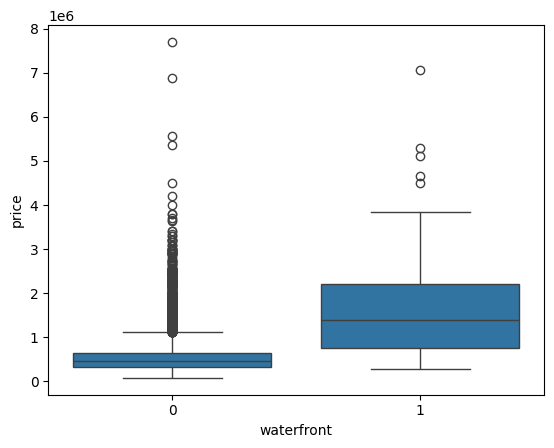

In [34]:
sns.boxplot(x="waterfront", y="price", data=df)

### 3.3 Price vs. above-ground area
`sqft_above` is **positively correlated** with price: larger houses tend to sell for more.

(0.0, 8081250.0)

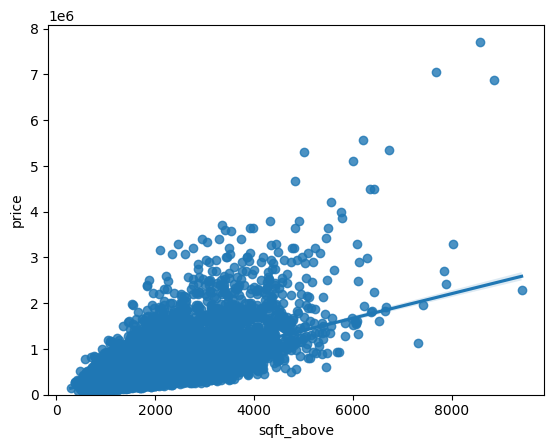

In [35]:
sns.regplot(x="sqft_above", y="price", data=df)
plt.ylim(0,)

### 3.4 Correlation with price
The features most correlated with `price` are:

| Feature | Correlation |
|---|---|
| `sqft_living` | 0.70 |
| `grade` | 0.67 |
| `sqft_above` | 0.61 |
| `sqft_living15` | 0.59 |
| `bathrooms` | 0.53 |

Features such as `long`, `condition` and `zipcode` show almost no linear relationship with price.

In [36]:
df_numeric = df.select_dtypes(include=[np.number])
df_numeric.corr()['price'].sort_values()

,price
zipcode,-0.053203
long,0.021626
condition,0.036362
yr_built,0.054012
sqft_lot15,0.082447
sqft_lot,0.089661
yr_renovated,0.126434
floors,0.256794
waterfront,0.266369
lat,0.307003


## 4. Model development

### 4.1 Baseline: a weak predictor
A linear regression using only longitude gives R² ≈ 0.0005, confirming that this feature alone has no predictive power.

In [37]:

X = df[['long']]
Y = df['price']
lm = LinearRegression()
lm.fit(X,Y)
lm.score(X, Y)

0.0004676943014898516

### 4.2 Simple linear regression with `sqft_living`
Living area alone explains about **49%** of the variance in price (R² ≈ 0.49).

In [38]:
X = df[['sqft_living']]
Y = df['price']
lm = LinearRegression()
lm.fit(X,Y)
lm.score(X, Y)

0.4928532179037931

### 4.3 Multiple linear regression
Using 11 features (`floors`, `waterfront`, `lat`, `bedrooms`, `sqft_basement`, `view`, `bathrooms`, `sqft_living15`, `sqft_above`, `grade`, `sqft_living`), R² rises to ≈ **0.66**. Combining variables clearly improves the fit.


In [39]:
features =["floors", "waterfront","lat" ,"bedrooms" ,"sqft_basement" ,"view" ,"bathrooms","sqft_living15","sqft_above","grade","sqft_living"]
X = df[features]
lm = LinearRegression()
lm.fit(X, Y)
lm.score(X, Y)

0.65769516660375

In [40]:
Input=[('scale',StandardScaler()),('polynomial', PolynomialFeatures(include_bias=False)),('model',LinearRegression())]

### 4.4 Pipeline: scaling + polynomial features + linear regression
A pipeline with `StandardScaler`, `PolynomialFeatures` and `LinearRegression` reaches R² ≈ **0.75**.

> **Note:** models in sections 4.1 to 4.4 are scored on the same data used for training (in-sample), so these values are optimistic and are not directly comparable with the test-set results in section 5.

In [41]:
pipe=Pipeline(Input)
pipe
X =X.astype(float)
pipe.fit(X,Y)
R2 = pipe.score(X, Y)
print("R²:", R2)

R²: 0.7513408515988733


## 5. Model evaluation and refinement
To measure performance on unseen data, the dataset is split into **85% training** (18,371 houses) and **15% testing** (3,242 houses). From here on, all R² values are computed on the **test set**.


In [42]:
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import train_test_split

In [43]:
features =["floors", "waterfront","lat" ,"bedrooms" ,"sqft_basement" ,"view" ,"bathrooms","sqft_living15","sqft_above","grade","sqft_living"]
X = df[features]
Y = df['price']

x_train, x_test, y_train, y_test = train_test_split(X, Y, test_size=0.15, random_state=1)


print("number of test samples:", x_test.shape[0])
print("number of training samples:",x_train.shape[0])

number of test samples: 3242
number of training samples: 18371


### 5.1 Ridge regression (alpha = 0.1)
Ridge adds regularization to reduce overfitting. Test R² ≈ **0.65**.

In [44]:
from sklearn.linear_model import Ridge

In [45]:
RigeModel=Ridge(alpha=0.1)
RigeModel.fit(x_train, y_train)
R2_test = RigeModel.score(x_test, y_test)

print("R² test:", R2_test)

R² test: 0.6478759163939113


### 5.2 Ridge regression with 2nd-degree polynomial features
Adding polynomial terms lets the model capture non-linear relationships between features and price. Test R² improves to ≈ **0.70**.


In [46]:
pr=PolynomialFeatures(degree=2)
x_train_pr=pr.fit_transform(x_train[["floors", "waterfront","lat" ,"bedrooms" ,"sqft_basement" ,"view" ,"bathrooms","sqft_living15","sqft_above","grade","sqft_living"]])
x_test_pr=pr.fit_transform(x_test[["floors", "waterfront","lat" ,"bedrooms" ,"sqft_basement" ,"view" ,"bathrooms","sqft_living15","sqft_above","grade","sqft_living"]])
RigeModel=Ridge(alpha=0.1)
RigeModel.fit(x_train_pr, y_train)
R2_test = RigeModel.score(x_test_pr, y_test)

print("R² test:", R2_test)

R² test: 0.7002744255133796


## 6. Conclusions

| Model | R² | Evaluated on |
|---|---|---|
| Linear regression (`long`) | 0.0005 | Training |
| Linear regression (`sqft_living`) | 0.49 | Training |
| Multiple linear regression (11 features) | 0.66 | Training |
| Polynomial pipeline (11 features) | 0.75 | Training |
| Ridge (11 features) | 0.65 | Test |
| Ridge + polynomial degree 2 | **0.70** | Test |

**Key takeaways**
- Living area, building grade and above-ground area are the strongest drivers of price.
- Combining features improves the model substantially (R² from 0.49 to 0.66).
- Non-linear terms add value: on unseen data, Ridge with polynomial features (R² ≈ 0.70) outperforms plain Ridge (R² ≈ 0.65).

**Limitations and next steps**
- Training and test R² are mixed in the comparison above; a fair comparison would score every model on the test set.
- Missing values were imputed with the mean, which produces fractional bedroom counts; the median or a more careful approach could be tested.
- Location variables (`zipcode`, `lat`, `long`) were used only linearly; geographic features could be engineered further.
- Other models (e.g., random forest or gradient boosting) and cross-validation could be explored.
